Throughout this notebook, we use \(D_1\) to denote the property that the sequential model stochastically dominates the static model in the number of occupied sites. And \(D_2\) to denote the property that the static model stochastically dominates the static model.


# Unfriendly Seating Process — Generalized Graph Model

This notebook illustrates the generalized (graph-based) unfriendly seating
process using three modules:

1. **Calc_PerGraph**: given a graph's adjacency matrix, computes the static
   and sequential occupied-count distributions and checks D_1 / D_2
   stochastic dominance for that single graph.
2. **Graph**: visualizes a graph together with every distinct blocking limit
   (final saturated state) reachable by the process.
3. **GeneralSearch**: scans all graphs on n vertices (optionally bounded by
   degree) to find the first one that fails a given dominance property.

First, a few example graphs are analyzed individually: a path graph, all
cycle graphs up to n=6, and a tree. Then GeneralSearch is used to confirm
D_1 holds across broader families of graphs.

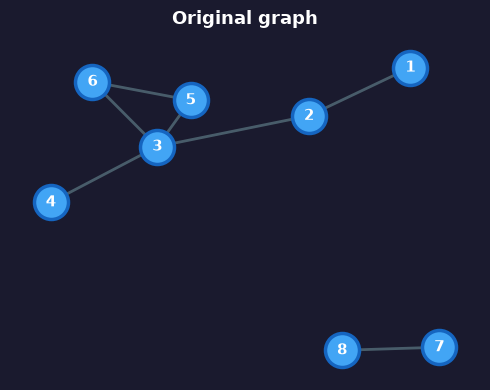


  Nodes: 8   |   Edges: 7
  Distinct blocking limits: 10



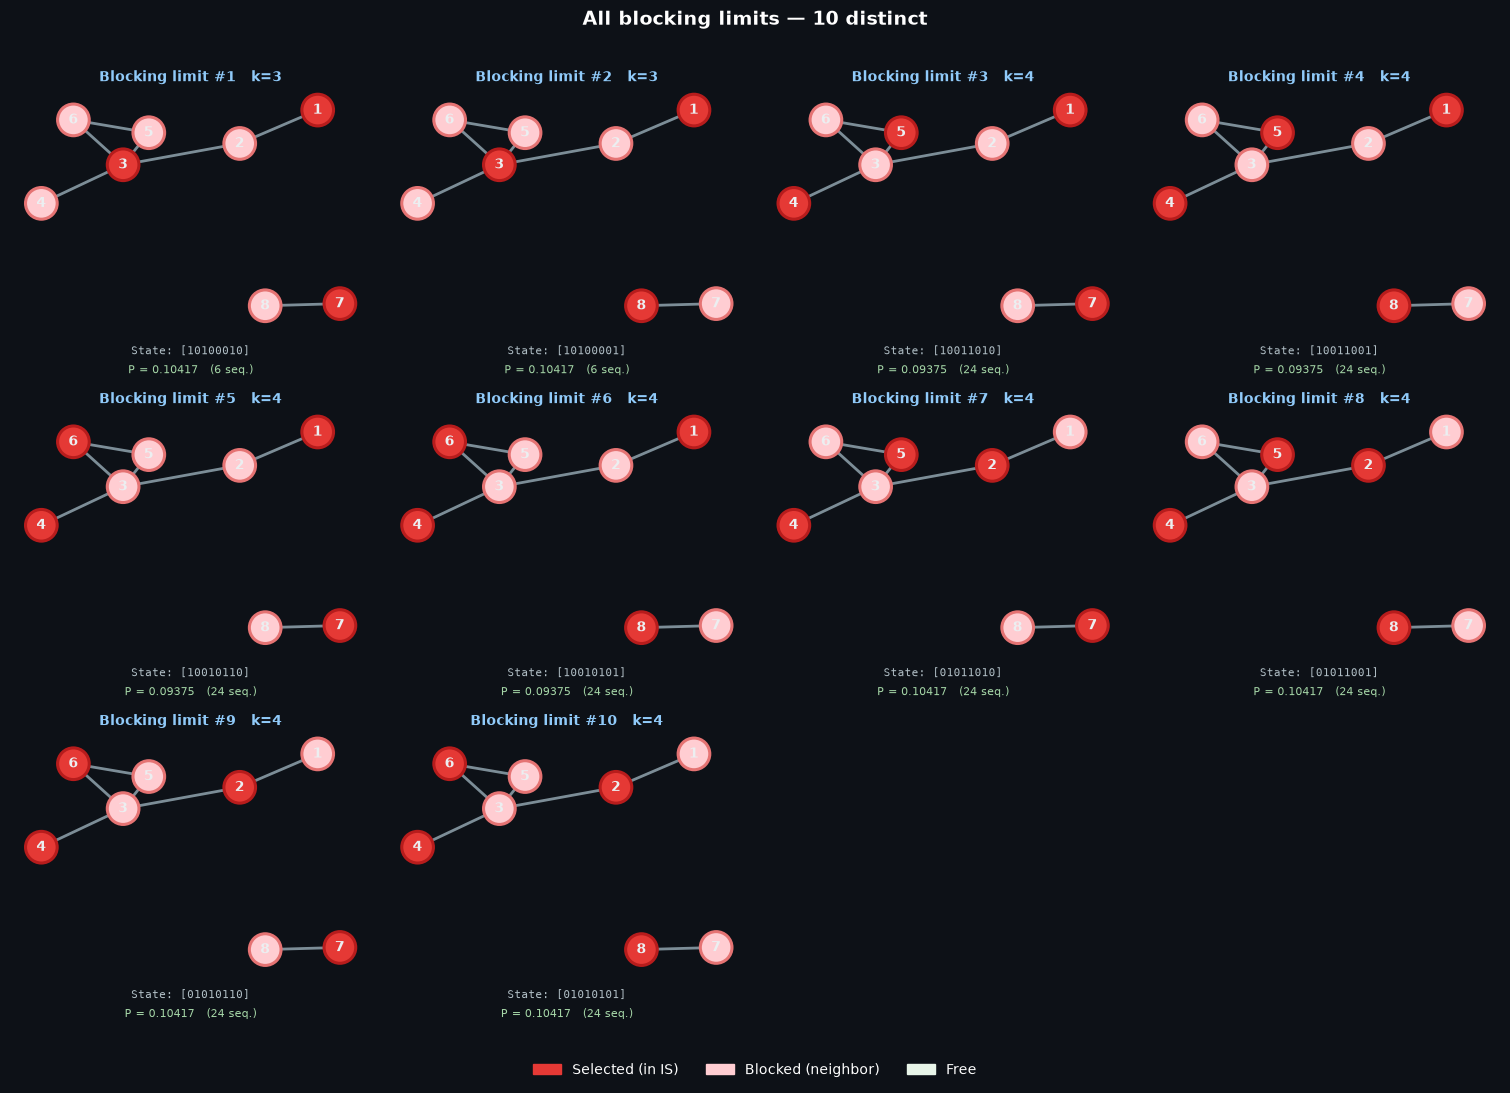

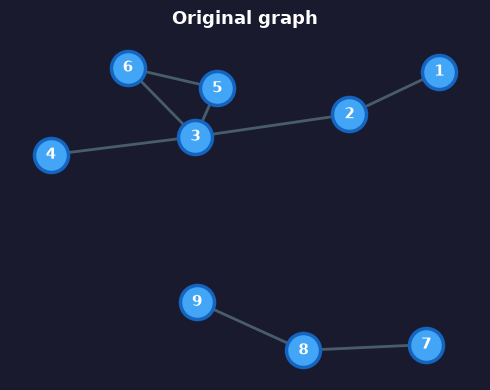


  Nodes: 9   |   Edges: 8
  Distinct blocking limits: 10



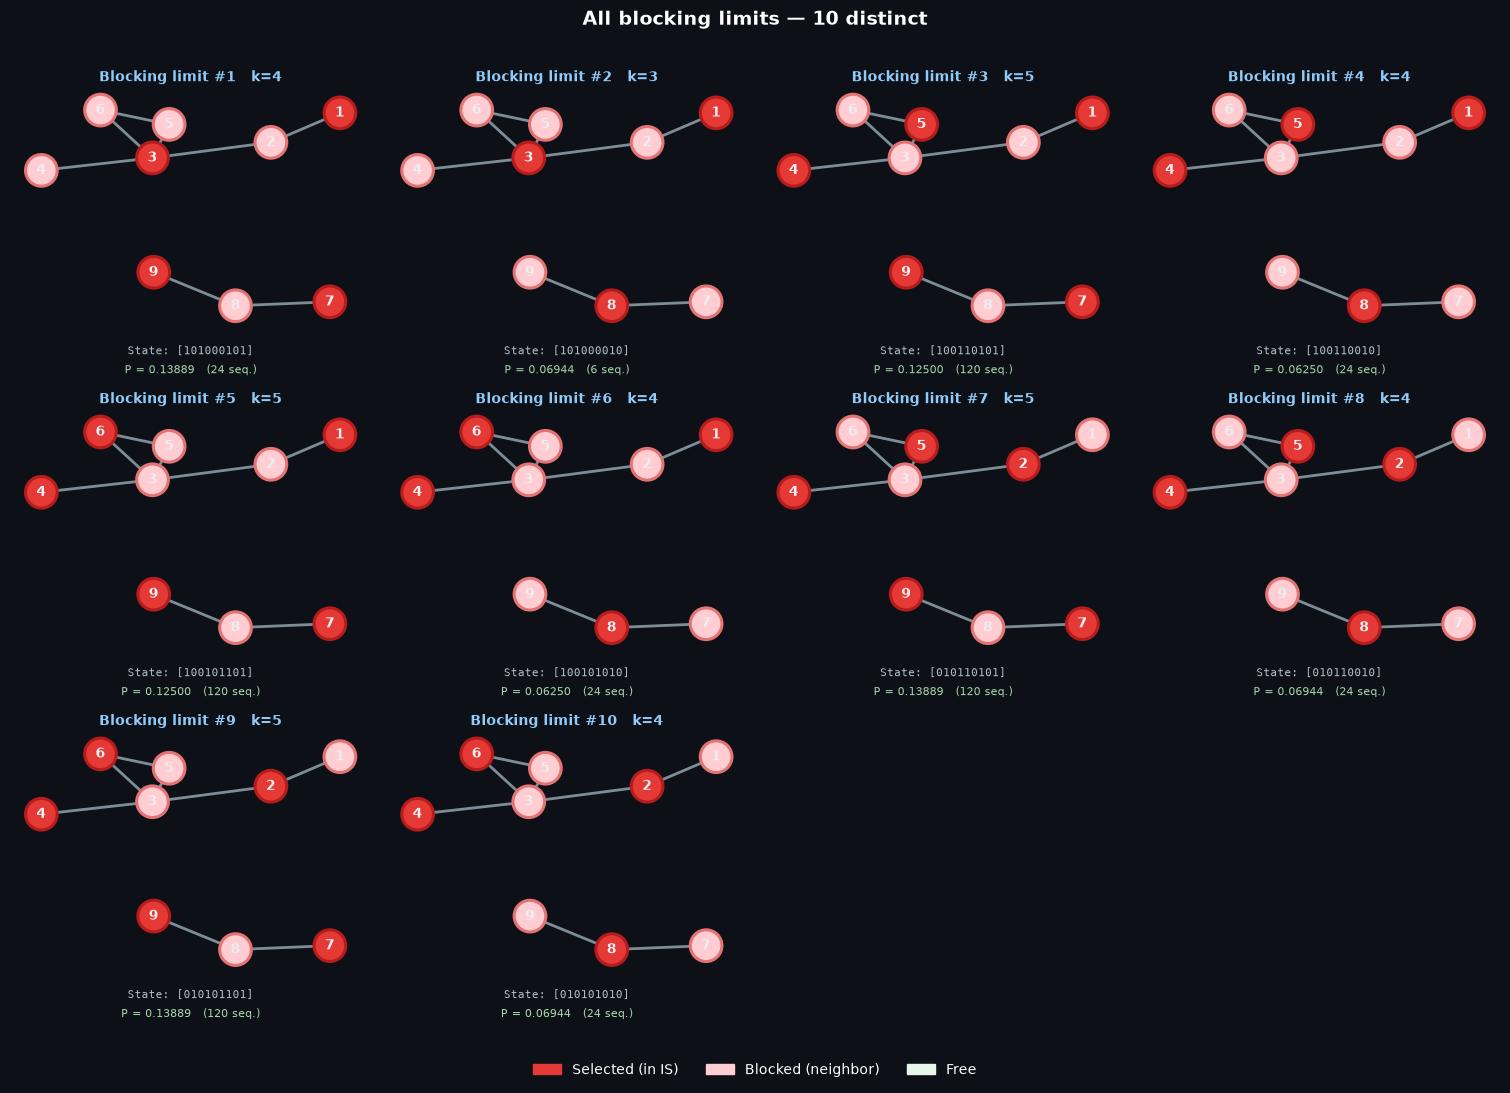

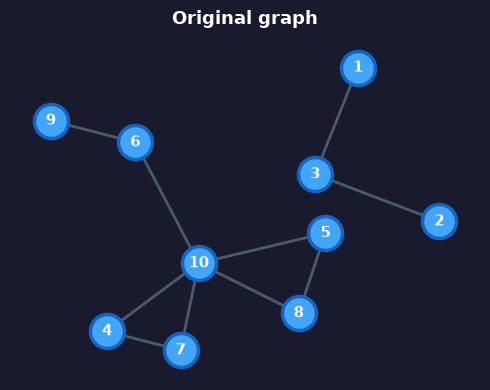


  Nodes: 10   |   Edges: 10
  Distinct blocking limits: 18



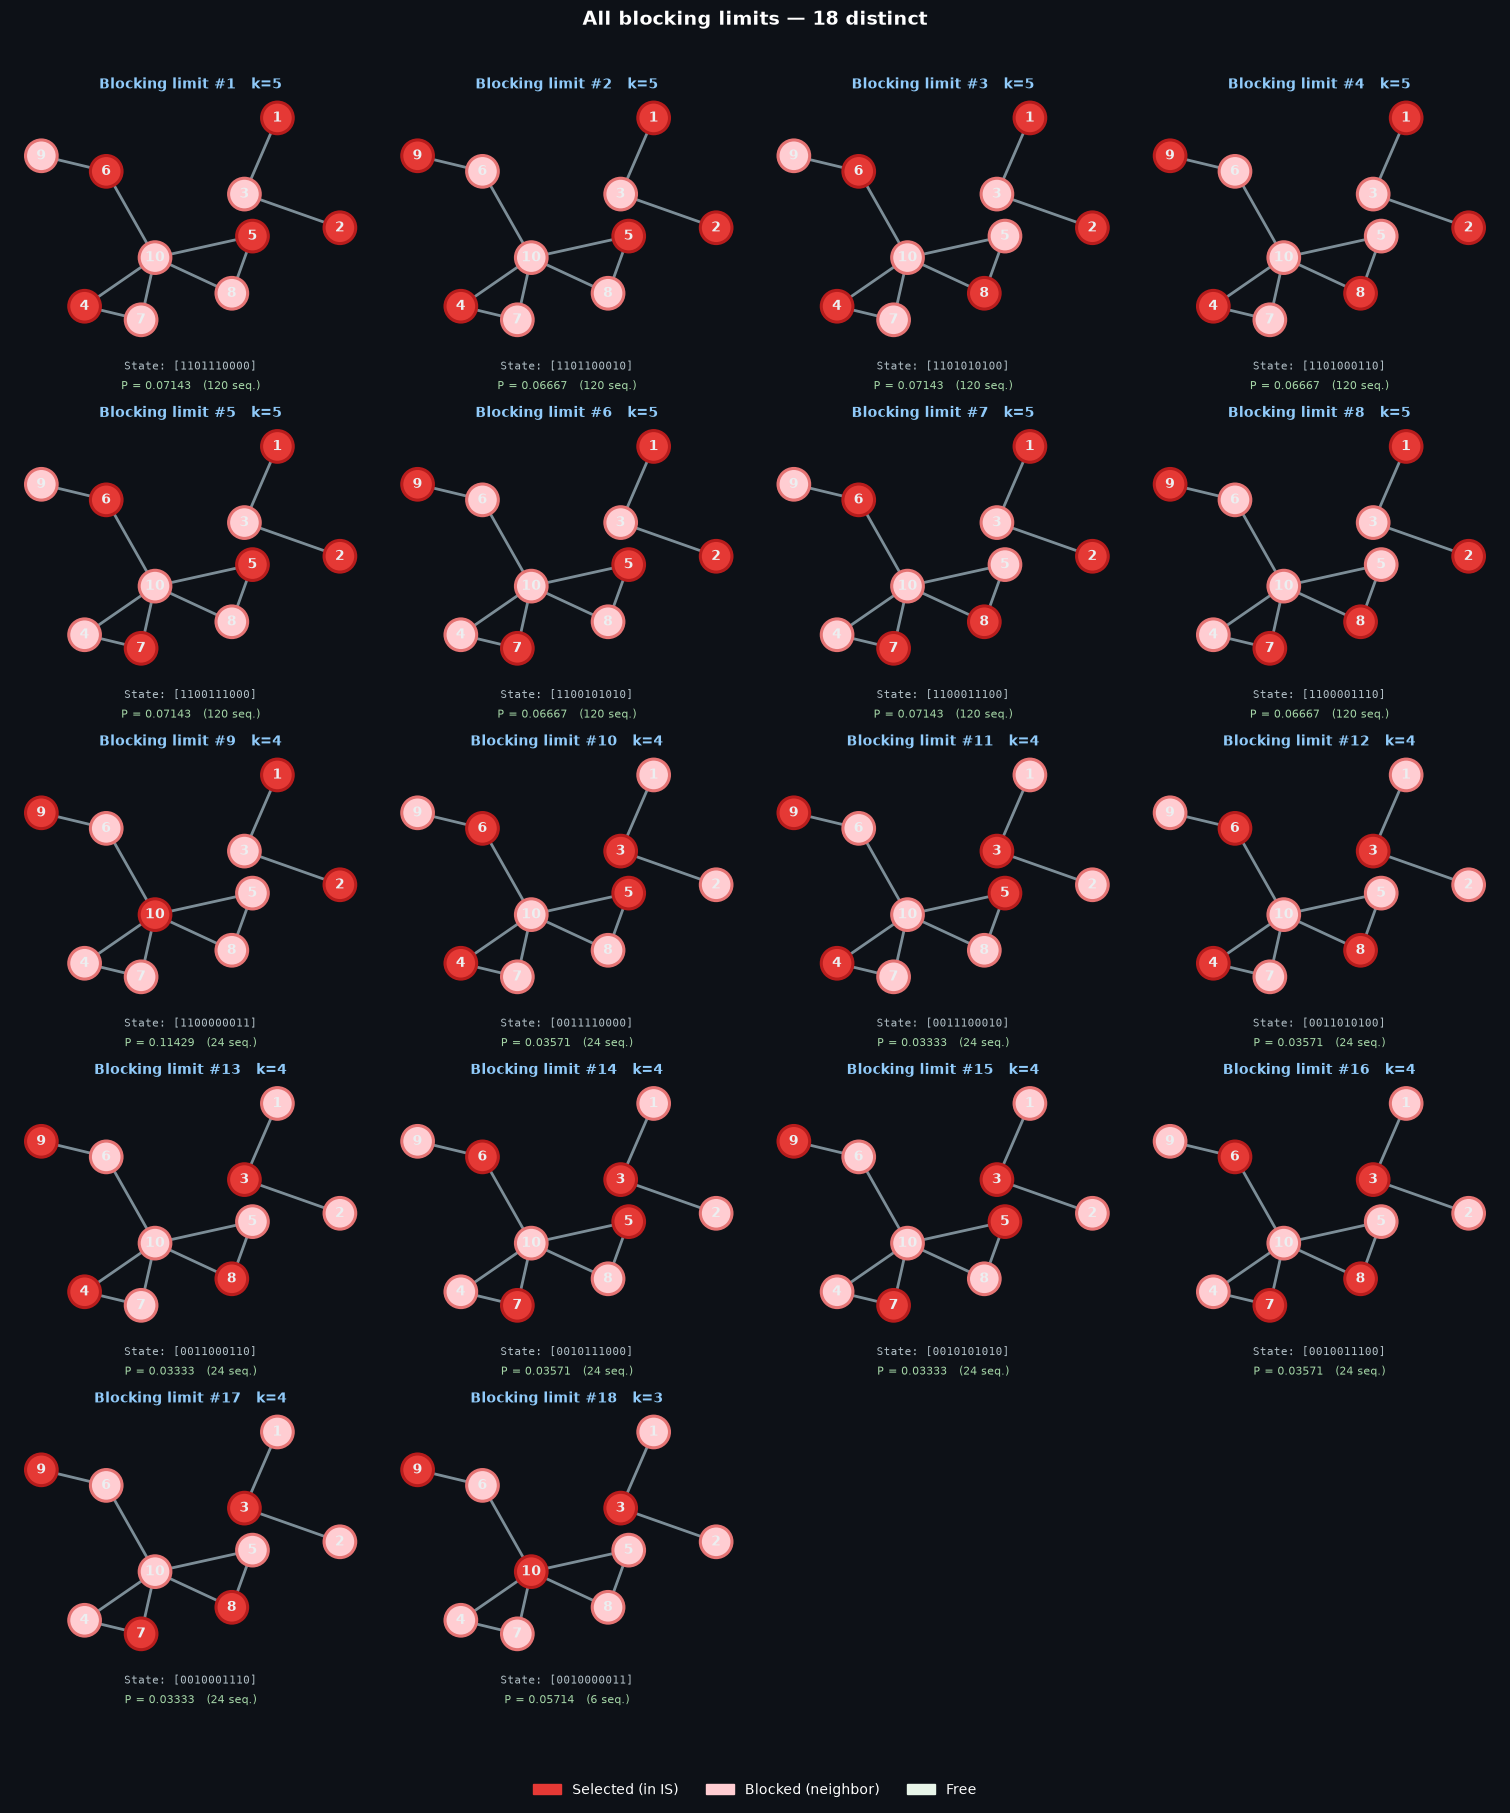

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "Source"))

from Calc_PerGraph import analyze_graph_dominance
from Graph import visualize_blocking_limits
from GeneralSearch import find_first_dominance_failure

## Example graph constructors

Helper functions to build the adjacency matrices used in the examples below.

In [2]:
def path_graph_matrix(n):
    """Adjacency matrix of the path graph (line graph) on n vertices: 1-2-3-...-n."""
    matrix = [[0] * n for _ in range(n)]
    for i in range(n - 1):
        matrix[i][i + 1] = matrix[i + 1][i] = 1
    return matrix


def cycle_graph_matrix(n):
    """
    Adjacency matrix of the cycle graph on n vertices.
    n = 1: single isolated vertex (no self-loop, since the graph is simple).
    n = 2: a single edge between the two vertices (a 2-cycle is not a simple
    graph, so this is the closest simple-graph analogue).
    n >= 3: standard cycle 1-2-3-...-n-1.
    """
    matrix = [[0] * n for _ in range(n)]
    if n == 1:
        return matrix
    if n == 2:
        matrix[0][1] = matrix[1][0] = 1
        return matrix

    for i in range(n):
        j = (i + 1) % n
        matrix[i][j] = matrix[j][i] = 1
    return matrix


def matrix_from_edges(n, edges):
    """Adjacency matrix on n vertices (0-indexed) built from an edge list."""
    matrix = [[0] * n for _ in range(n)]
    for i, j in edges:
        matrix[i][j] = matrix[j][i] = 1
    return matrix

## Line graph (path), n = 6

Adjacency matrix:
[0, 1, 0, 0, 0, 0]
[1, 0, 1, 0, 0, 0]
[0, 1, 0, 1, 0, 0]
[0, 0, 1, 0, 1, 0]
[0, 0, 0, 1, 0, 1]
[0, 0, 0, 0, 1, 0]
   k |     Cum_stat |      Cum_seq
----------------------------------
   2 |     0.200000 |     0.111111
   3 |     1.000000 |     1.000000

D_1 holds: the sequential model dominates the static model.


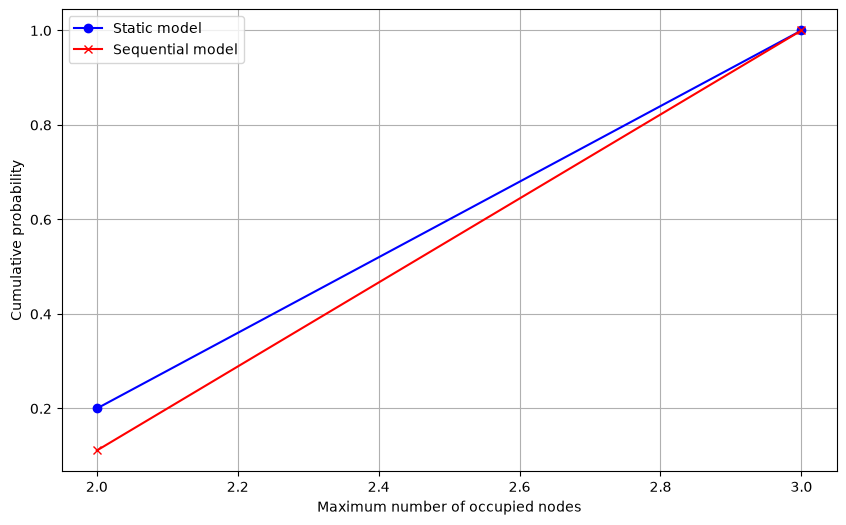

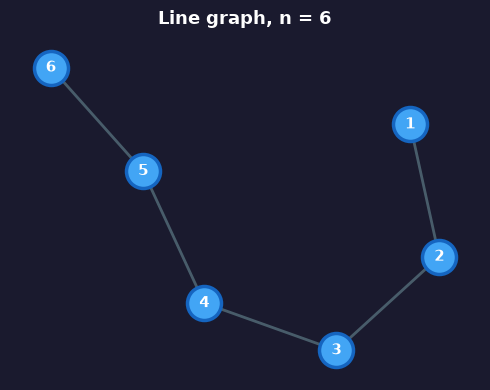


  Nodes: 6   |   Edges: 5
  Distinct blocking limits: 5



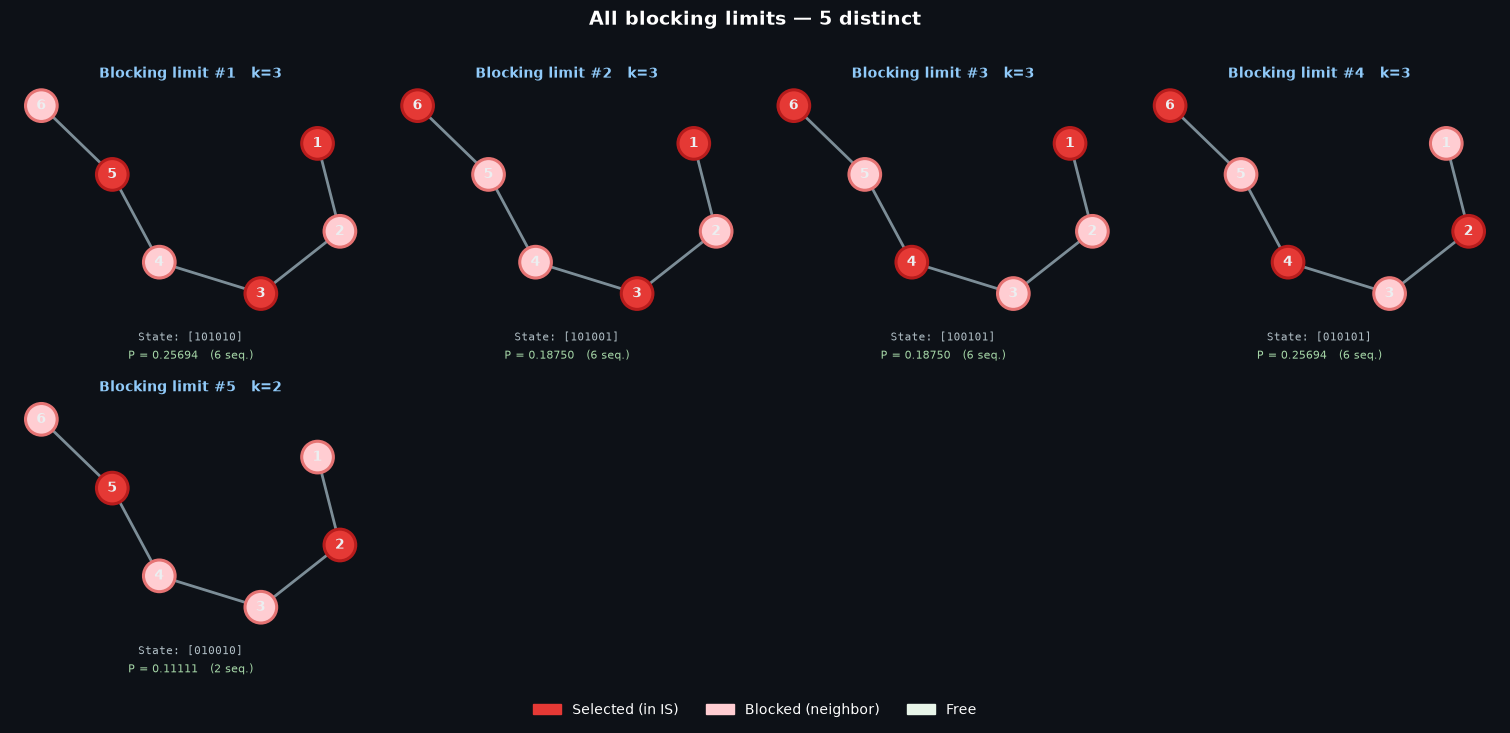

   k |     Cum_stat |      Cum_seq
----------------------------------
   2 |     0.111111 |     0.150000
   3 |     0.555556 |     0.416667
   4 |     1.000000 |     1.000000

Neither D_1 nor D_2 holds: the cumulative distributions cross.


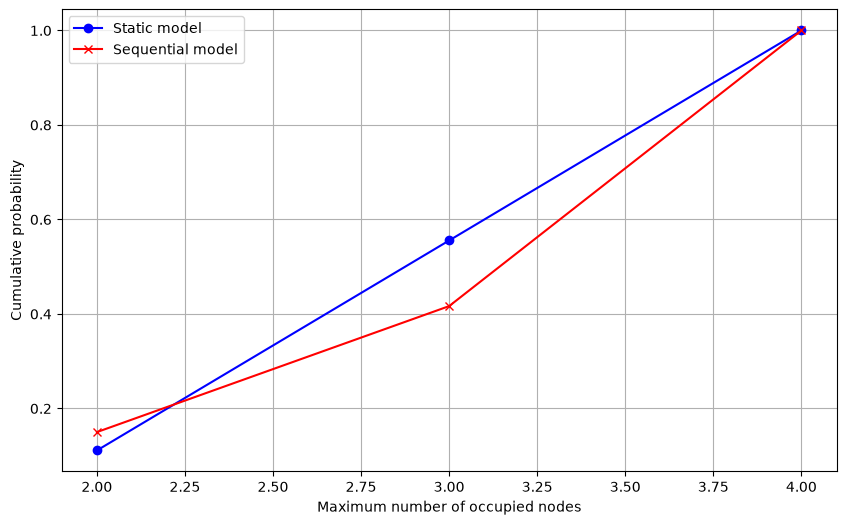

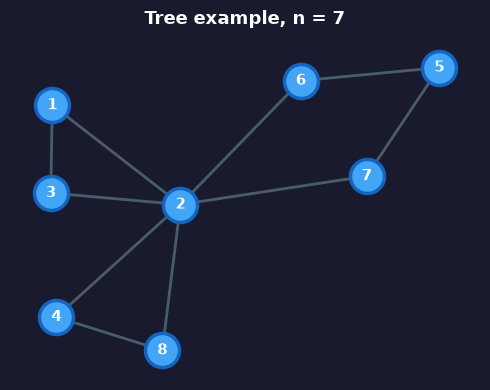


  Nodes: 8   |   Edges: 10
  Distinct blocking limits: 9



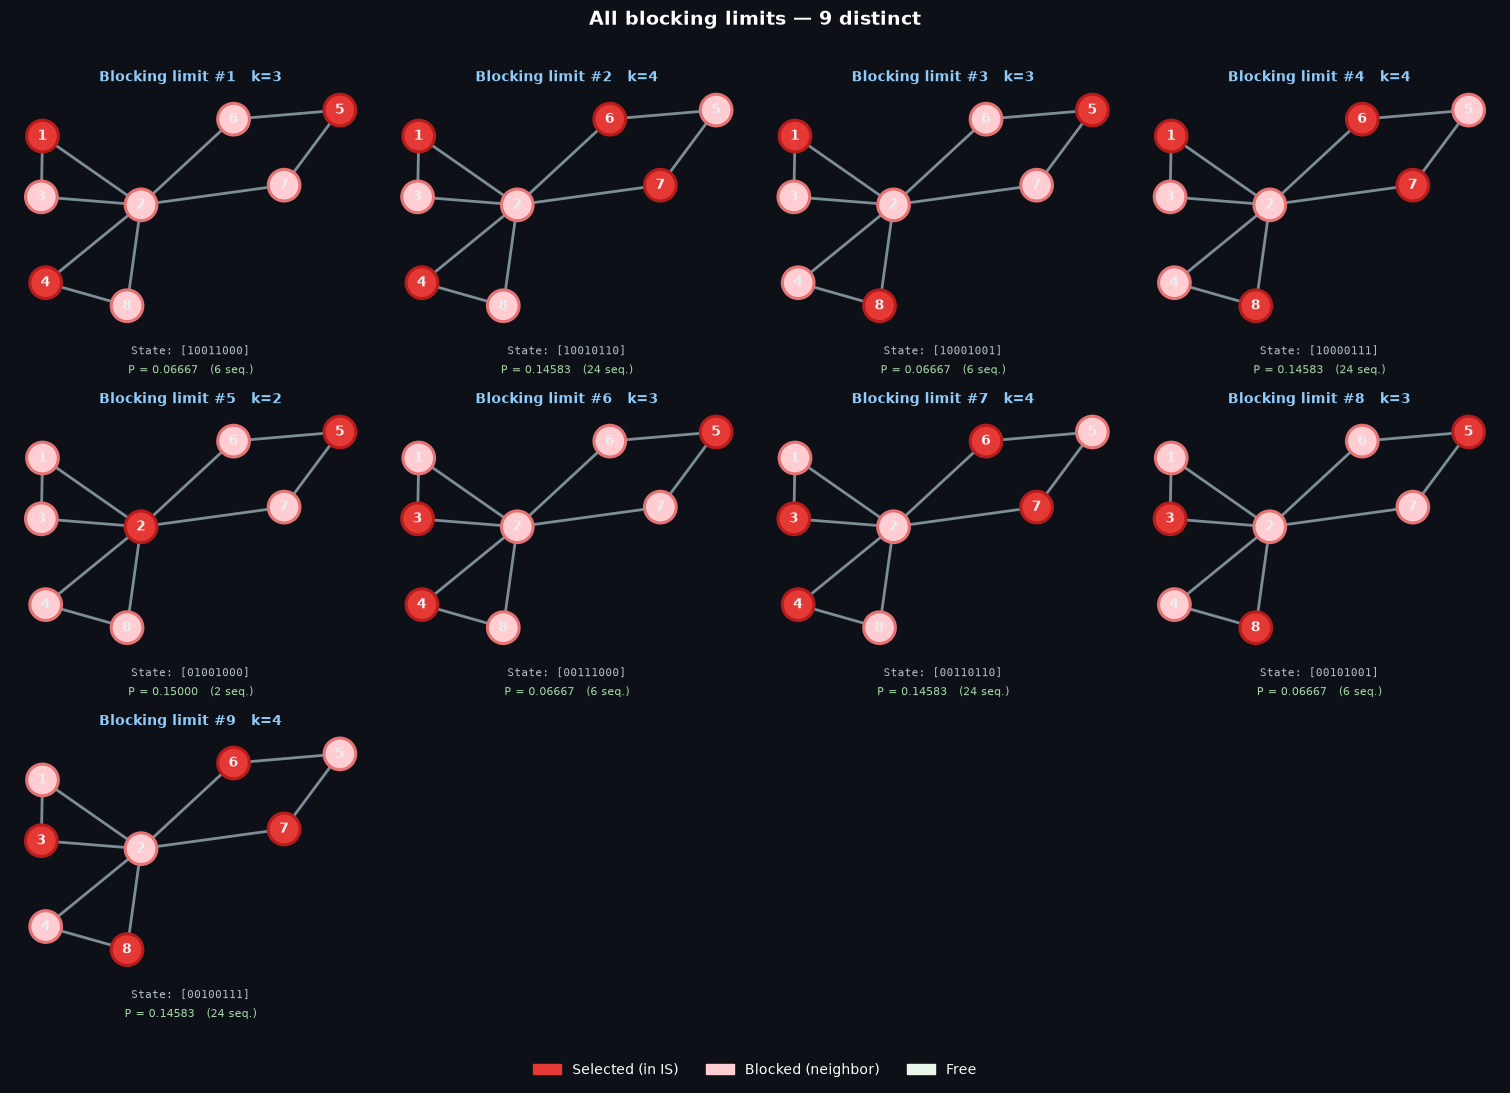

In [8]:
line_matrix = path_graph_matrix(6)

print("Adjacency matrix:")
for row in line_matrix:
    print(row)

analyze_graph_dominance(line_matrix)
visualize_blocking_limits(line_matrix, graph_title="Line graph, n = 6")


A = [
    [0, 1, 1, 0, 0, 0, 0, 0],
    [1, 0, 1, 1, 0, 1, 1, 1],
    [1, 1, 0, 0, 0, 0, 0, 0],
    [0, 1, 0, 0, 0, 0, 0, 1],
    [0, 0, 0, 0, 0, 1, 1, 0],
    [0, 1, 0, 0, 1, 0, 0, 0],
    [0, 1, 0, 0, 1, 0, 0, 0],
    [0, 1, 0, 1, 0, 0, 0, 0]
]
analyze_graph_dominance(A)
visualize_blocking_limits(A, graph_title="Tree example, n = 7")

## Cycle graphs, n = 1 to 6


--- Cycle graph, n = 1 ---
Adjacency matrix:
[0]
   k |     Cum_stat |      Cum_seq
----------------------------------
   1 |     1.000000 |     1.000000

Both cumulative distributions coincide (D_1 and D_2 both hold).


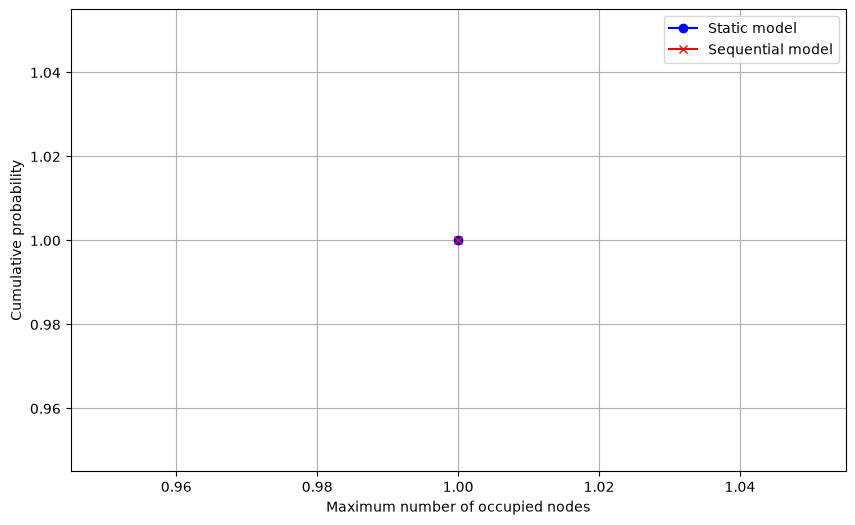

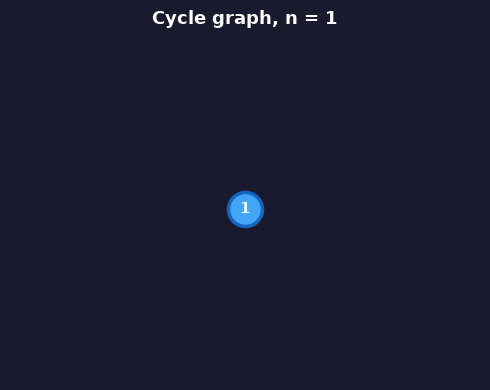


  Nodes: 1   |   Edges: 0
  Distinct blocking limits: 1



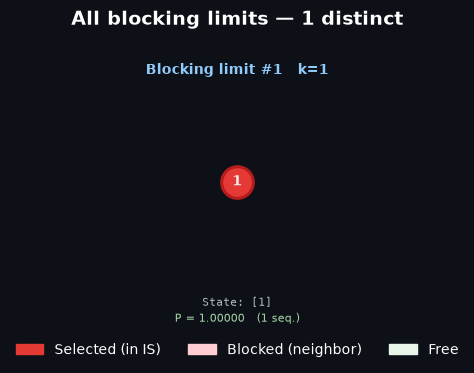


--- Cycle graph, n = 2 ---
Adjacency matrix:
[0, 1]
[1, 0]
   k |     Cum_stat |      Cum_seq
----------------------------------
   1 |     1.000000 |     1.000000

Both cumulative distributions coincide (D_1 and D_2 both hold).


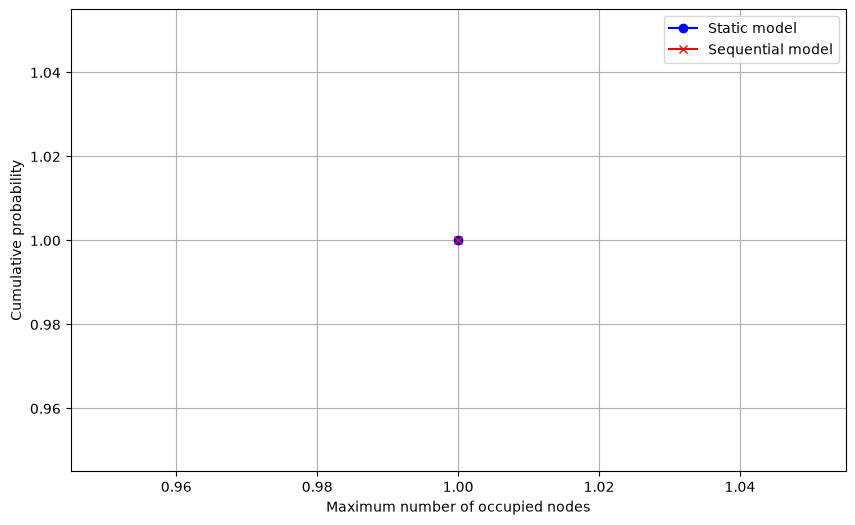

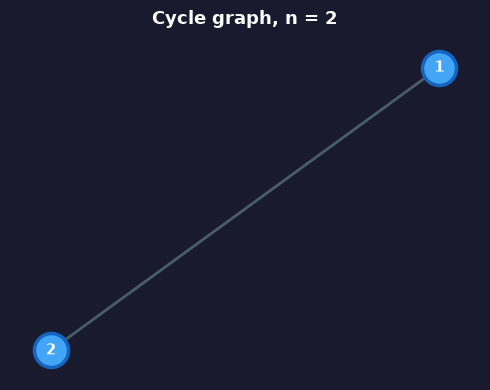


  Nodes: 2   |   Edges: 1
  Distinct blocking limits: 2



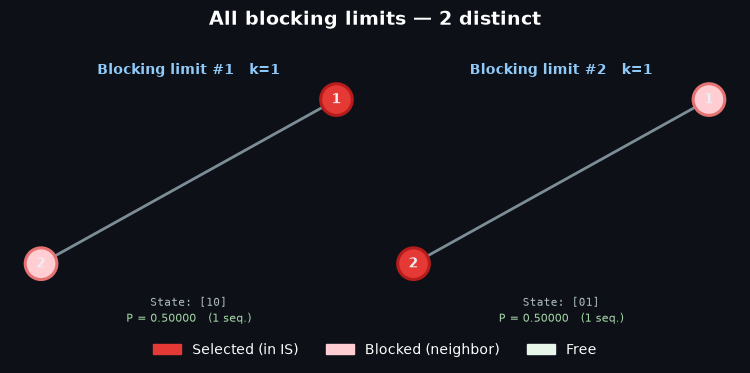


--- Cycle graph, n = 3 ---
Adjacency matrix:
[0, 1, 1]
[1, 0, 1]
[1, 1, 0]
   k |     Cum_stat |      Cum_seq
----------------------------------
   1 |     1.000000 |     1.000000

Both cumulative distributions coincide (D_1 and D_2 both hold).


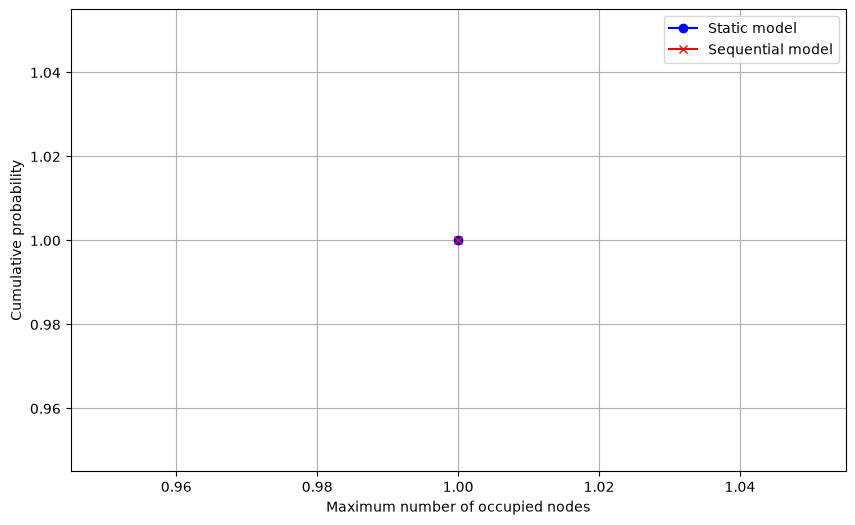

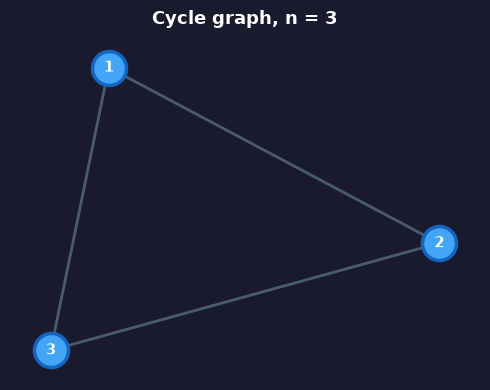


  Nodes: 3   |   Edges: 3
  Distinct blocking limits: 3



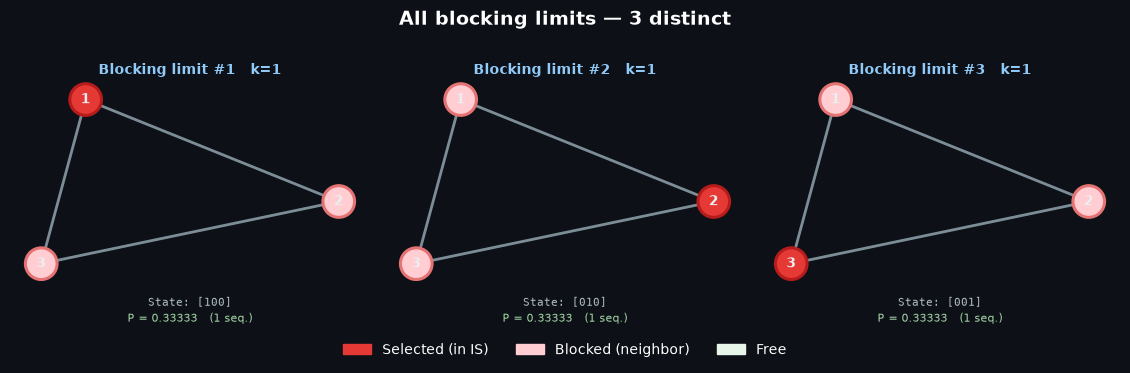


--- Cycle graph, n = 4 ---
Adjacency matrix:
[0, 1, 0, 1]
[1, 0, 1, 0]
[0, 1, 0, 1]
[1, 0, 1, 0]
   k |     Cum_stat |      Cum_seq
----------------------------------
   2 |     1.000000 |     1.000000

Both cumulative distributions coincide (D_1 and D_2 both hold).


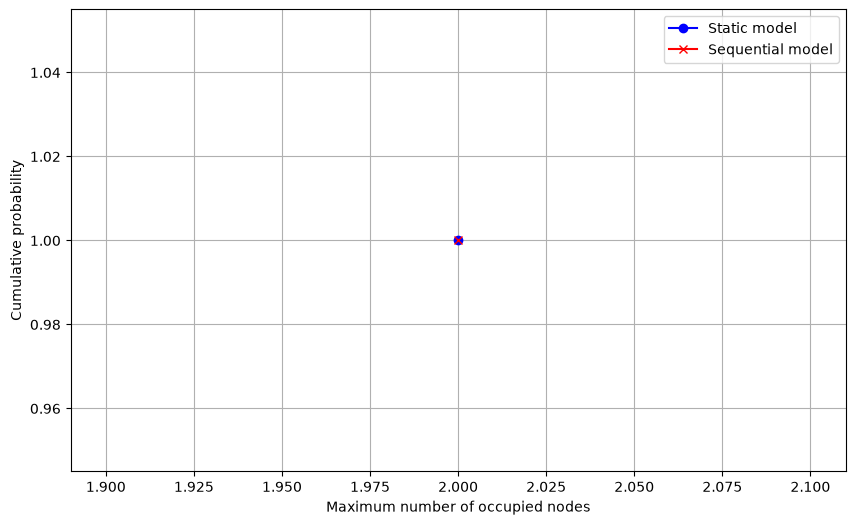

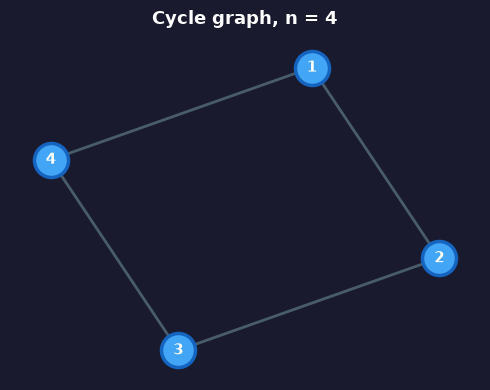


  Nodes: 4   |   Edges: 4
  Distinct blocking limits: 2



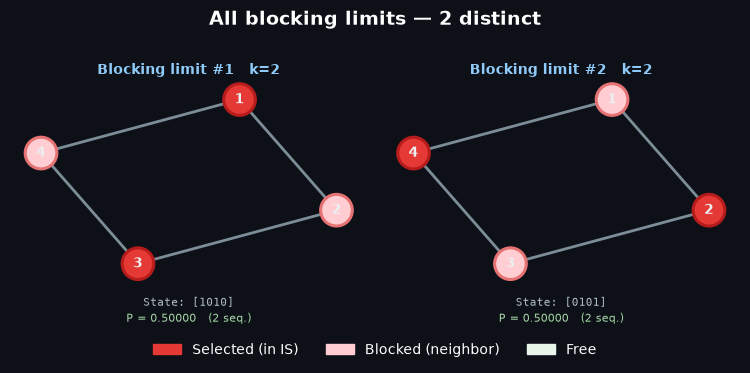


--- Cycle graph, n = 5 ---
Adjacency matrix:
[0, 1, 0, 0, 1]
[1, 0, 1, 0, 0]
[0, 1, 0, 1, 0]
[0, 0, 1, 0, 1]
[1, 0, 0, 1, 0]
   k |     Cum_stat |      Cum_seq
----------------------------------
   2 |     1.000000 |     1.000000

Both cumulative distributions coincide (D_1 and D_2 both hold).


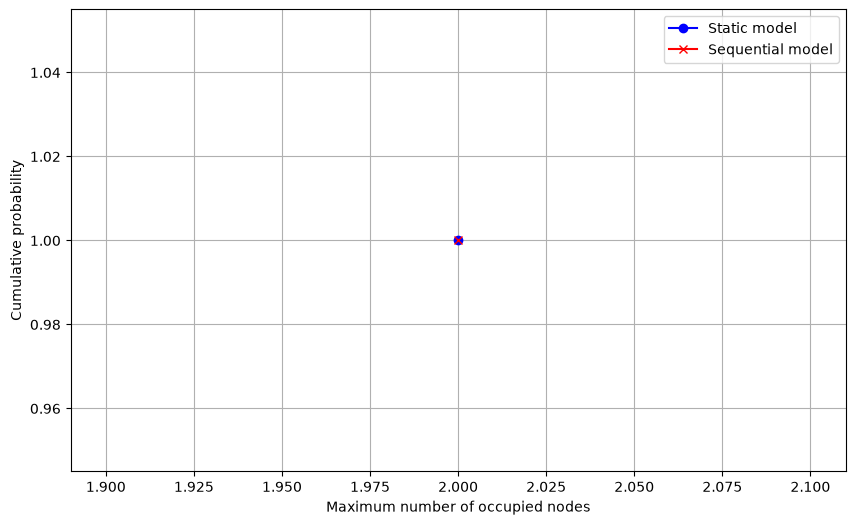

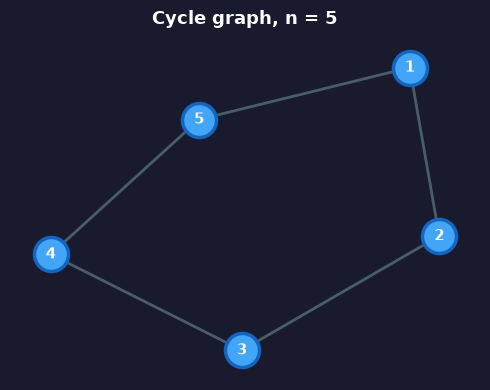


  Nodes: 5   |   Edges: 5
  Distinct blocking limits: 5



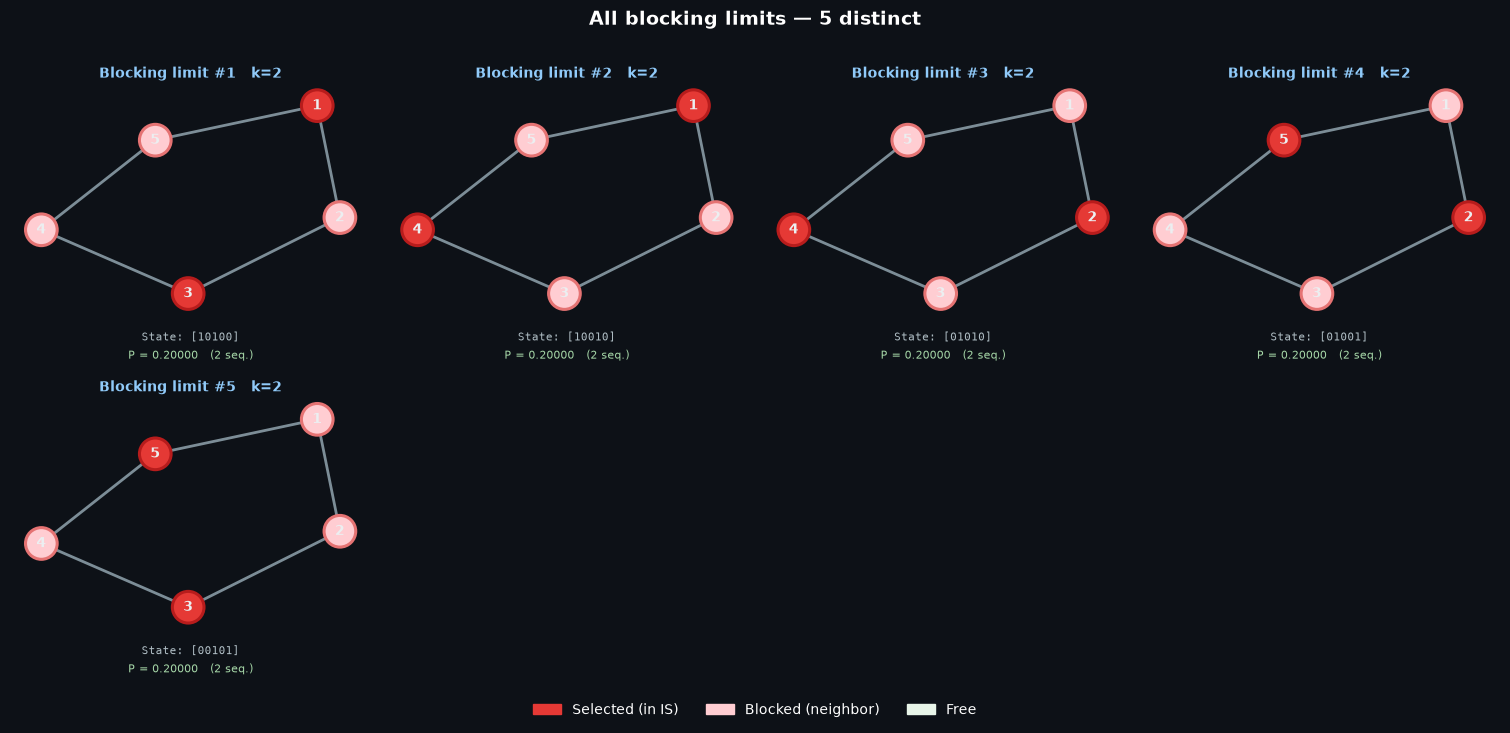


--- Cycle graph, n = 6 ---
Adjacency matrix:
[0, 1, 0, 0, 0, 1]
[1, 0, 1, 0, 0, 0]
[0, 1, 0, 1, 0, 0]
[0, 0, 1, 0, 1, 0]
[0, 0, 0, 1, 0, 1]
[1, 0, 0, 0, 1, 0]
   k |     Cum_stat |      Cum_seq
----------------------------------
   2 |     0.600000 |     0.333333
   3 |     1.000000 |     1.000000

D_1 holds: the sequential model dominates the static model.


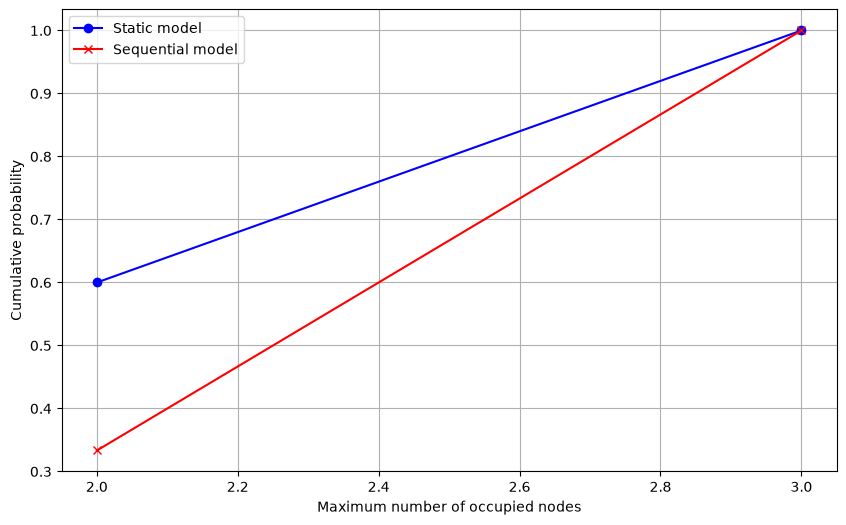

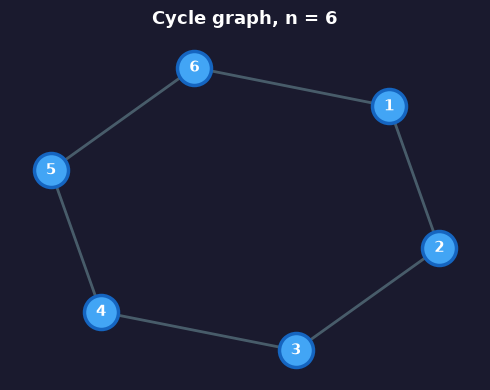


  Nodes: 6   |   Edges: 6
  Distinct blocking limits: 5



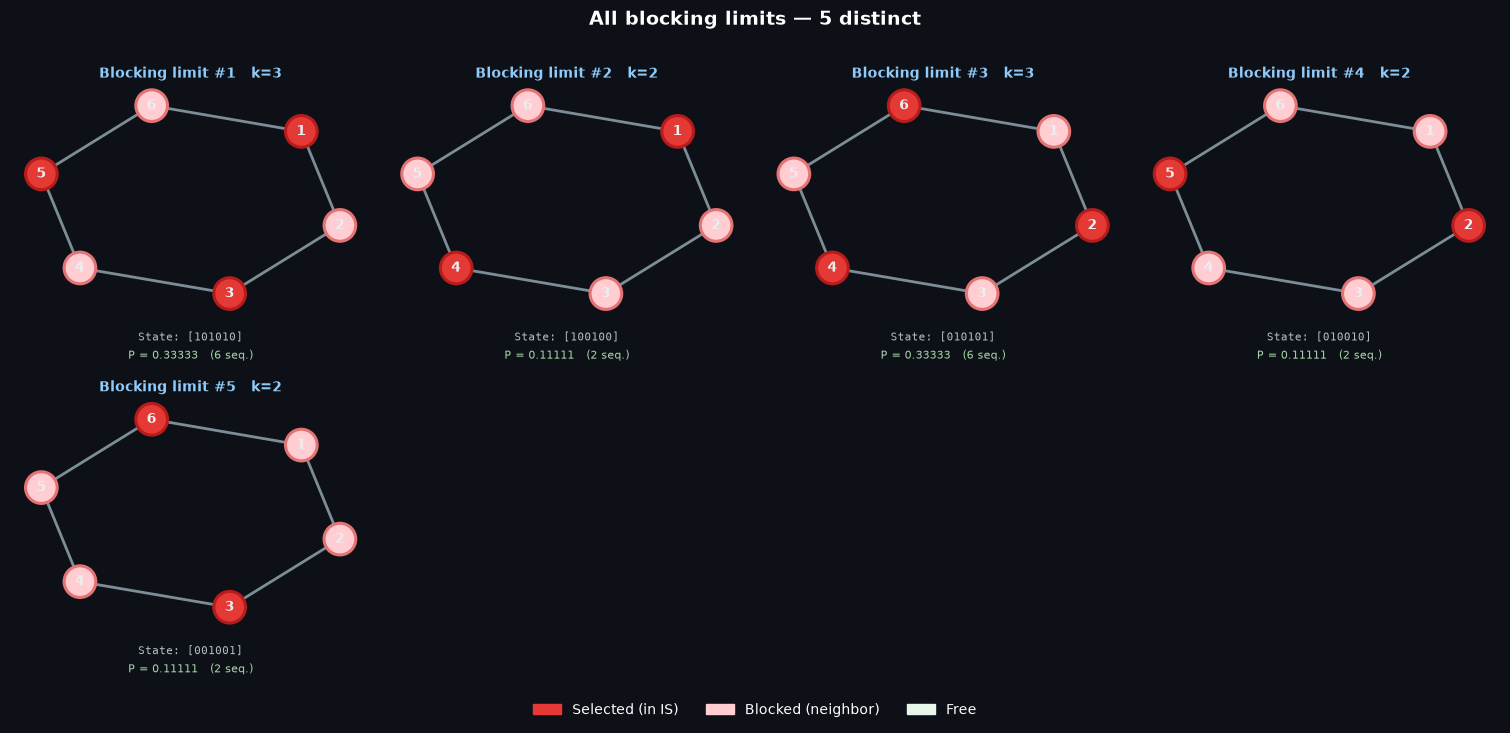

In [4]:
for n in range(1, 7):
    cycle_matrix = cycle_graph_matrix(n)

    print(f"\n--- Cycle graph, n = {n} ---")
    print("Adjacency matrix:")
    for row in cycle_matrix:
        print(row)

    analyze_graph_dominance(cycle_matrix)
    visualize_blocking_limits(cycle_matrix, graph_title=f"Cycle graph, n = {n}")

## Tree example

A small binary tree on 7 vertices: root 1, connected to 2 and 3; 2 connected
to 4 and 5; 3 connected to 6 and 7.

Adjacency matrix:
[0, 1, 1, 0, 0, 0, 0]
[1, 0, 0, 1, 1, 0, 0]
[1, 0, 0, 0, 0, 1, 1]
[0, 1, 0, 0, 0, 0, 0]
[0, 1, 0, 0, 0, 0, 0]
[0, 0, 1, 0, 0, 0, 0]
[0, 0, 1, 0, 0, 0, 0]
   k |     Cum_stat |      Cum_seq
----------------------------------
   2 |     0.250000 |     0.095238
   3 |     0.750000 |     0.428571
   5 |     1.000000 |     1.000000

D_1 holds: the sequential model dominates the static model.


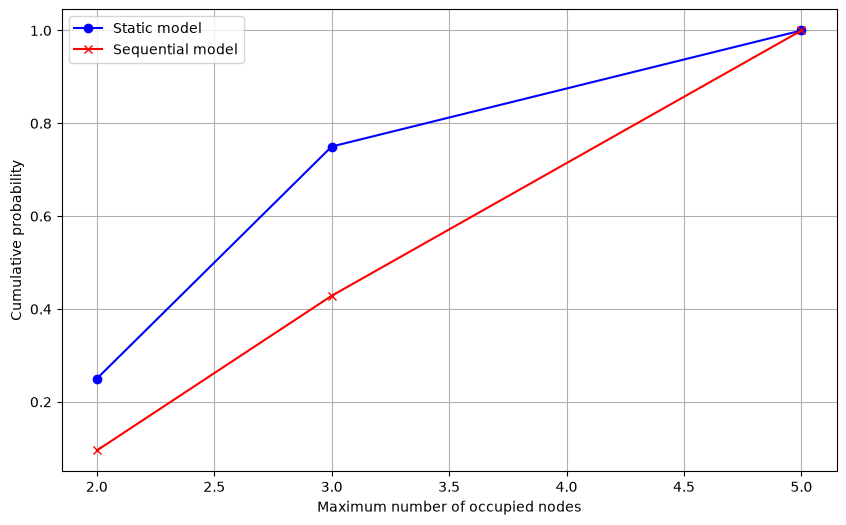

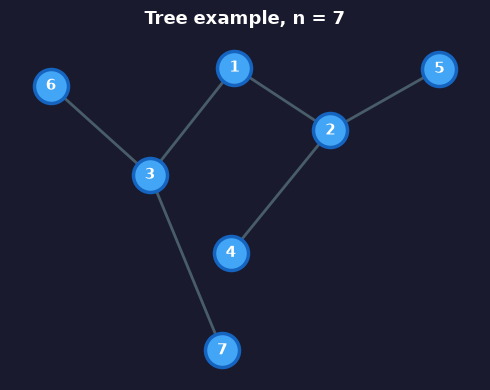


  Nodes: 7   |   Edges: 6
  Distinct blocking limits: 4



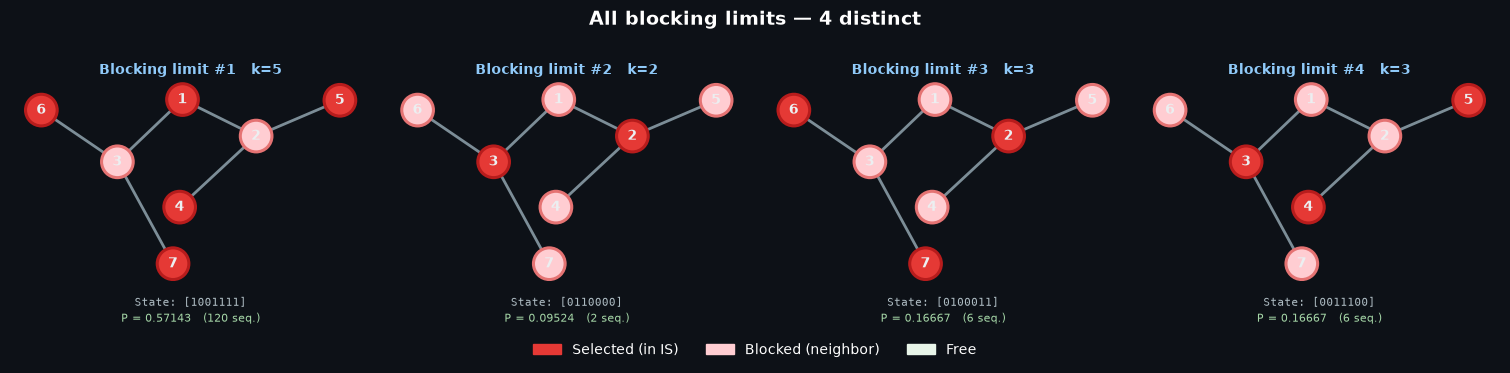

In [5]:
tree_edges = [(0, 1), (0, 2), (1, 3), (1, 4), (2, 5), (2, 6)]
tree_matrix = matrix_from_edges(7, tree_edges)

print("Adjacency matrix:")
for row in tree_matrix:
    print(row)

analyze_graph_dominance(tree_matrix)
visualize_blocking_limits(tree_matrix, graph_title="Tree example, n = 7")



## General search: D_1 across all graphs up to n = 5

Checks, for every n from 1 to 5, whether any connected graph on n vertices
fails D_1. If `find_first_dominance_failure` returns `None` for every n,
D_1 holds across the entire family.

In [6]:
all_hold_small = True

for n in range(1, 6):
    failure = find_first_dominance_failure(n, mode=0)
    if failure is None:
        print(f"n = {n}: D_1 holds for every graph.")
    else:
        all_hold_small = False
        print(f"n = {n}: D_1 FAILS for a graph with adjacency matrix:")
        for row in failure["adjacency_matrix"]:
            print(f"  {row}")

print()
if all_hold_small:
    print("D_1 holds for every graph on up to 5 vertices.")
else:
    print("D_1 does not hold for every graph on up to 5 vertices.")

n = 1: D_1 holds for every graph.
n = 2: D_1 holds for every graph.
n = 3: D_1 holds for every graph.
n = 4: D_1 holds for every graph.
n = 5: D_1 holds for every graph.

D_1 holds for every graph on up to 5 vertices.


## General search: D_1 for max-degree-3 graphs up to n = 10

Same check, restricted to graphs with maximum degree at most 3, for n from
1 to 10.

In [7]:
all_hold_bounded = True

for n in range(1, 11):
    failure = find_first_dominance_failure(n, mode=0, max_degree=3)
    if failure is None:
        print(f"n = {n}: D_1 holds for every graph with max degree <= 3.")
    else:
        all_hold_bounded = False
        print(f"n = {n}: D_1 FAILS for a graph with adjacency matrix:")
        for row in failure["adjacency_matrix"]:
            print(f"  {row}")

print()
if all_hold_bounded:
    print("D_1 holds for every graph on up to 10 vertices with max degree 3.")
else:
    print("D_1 does not hold for every graph on up to 10 vertices with max degree 3.")

n = 1: D_1 holds for every graph with max degree <= 3.
n = 2: D_1 holds for every graph with max degree <= 3.
n = 3: D_1 holds for every graph with max degree <= 3.
n = 4: D_1 holds for every graph with max degree <= 3.
n = 5: D_1 holds for every graph with max degree <= 3.
n = 6: D_1 holds for every graph with max degree <= 3.
n = 7: D_1 holds for every graph with max degree <= 3.
n = 8: D_1 holds for every graph with max degree <= 3.
n = 9: D_1 holds for every graph with max degree <= 3.
n = 10: D_1 holds for every graph with max degree <= 3.

D_1 holds for every graph on up to 10 vertices with max degree 3.
